New York City Airbnb Open Data
Airbnb listings and metrics in NYC, NY, USA (2019)


1 Level A — Easy

In [79]:
import pandas as pd

In [80]:
df = pd.read_csv('AB_NYC_2019.csv')

In [81]:
df.shape

(48895, 16)

In [82]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


1.1 A1. Data Types & Attributes

Nominal - the data can be placed into categories and cannot be used in calculations

Ordinal - the data categories can be ordered/ranked, the difference between data cannot be measured

Discrete - distinct, separate and countable numerical values

Continuous - numerical values that can take on any value within a given range/continuum

In [83]:
data = [
    {"Attribute": "id", "Classification": "Nominal"},
    {"Attribute": "name", "Classification": "Nominal"},
    {"Attribute": "host_id", "Classification": "Nominal"},
    {"Attribute": "host_name", "Classification": "Nominal"},
    {"Attribute": "neighbourhood_group", "Classification": "Nominal"},
    {"Attribute": "neighbourhood", "Classification": "Nominal"},
    {"Attribute": "latitude", "Classification": "Continuous"},
    {"Attribute": "longitude", "Classification": "Continuous"},
    {"Attribute": "room_type", "Classification": "Nominal"},
    {"Attribute": "price", "Classification": "Continuous"},
    {"Attribute": "minimum_nights", "Classification": "Discrete"},
    {"Attribute": "number_of_reviews", "Classification": "Discrete"},
    {"Attribute": "last_review", "Classification": "Ordinal"},
    {"Attribute": "reviews_per_month", "Classification": "Continuous"},
    {"Attribute": "calculated_host_listings_count", "Classification": "Discrete"},
    {"Attribute": "availability_365", "Classification": "Discrete"},
]

classification_df = pd.DataFrame(data)
print(classification_df)

                         Attribute Classification
0                               id        Nominal
1                             name        Nominal
2                          host_id        Nominal
3                        host_name        Nominal
4              neighbourhood_group        Nominal
5                    neighbourhood        Nominal
6                         latitude     Continuous
7                        longitude     Continuous
8                        room_type        Nominal
9                            price     Continuous
10                  minimum_nights       Discrete
11               number_of_reviews       Discrete
12                     last_review        Ordinal
13               reviews_per_month     Continuous
14  calculated_host_listings_count       Discrete
15                availability_365       Discrete


id, host_id Nominal: unique identification without mathematical meaning

name, host_name Nominal: categorical data with no order and calculations

neighbourhood_group, neighbourhood Nominal: specific area names/groups that serve as qualitative categorical labels

latitude, longitude Continuous: geographic coordinates measured on a continuous scale with precise decimal values.

room_type Nominal: distinct property listing categories that cannot be inherently ordered or measured numerically.

minimum_nights, number_of_reviews, calculated_host_listings_count Discrete: countable values , which consist of non-negative whole integer units

price Discrete: price can be fractional values

last_review  Ordinal: dates represent ordered chronological points in time, allowing to rank listings from oldest to newest review date

reviews_per_month Continuous: calculated average rate of reviews per month, taking on fractional and decimal values

availability_365 Discrete: countable whole days per year that a listing is available for booking (ranging from 0 to 365)

1.2 A2. Descriptive Statistics

2. Compute: mean, median, mode, range, variance, standard deviation, IQR.

In [84]:
features = [
    "latitude",
    "longitude",
    "price",
    "minimum_nights",
    "number_of_reviews", 
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

stats_list = []

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    mode_series = df[col].mode()
    mode_val = mode_series.iloc[0] if not mode_series.empty else None

    stats_list.append({
        'Feature': col,
        'Mean': df[col].mean(),
        'Median': df[col].median(),
        'Mode': mode_val,
        'Range': df[col].max() - df[col].min(),
        'Variance': df[col].var(),
        'Std Dev': df[col].std(),
        'IQR': IQR,
    })

descriptive_stats = pd.DataFrame(stats_list).set_index('Feature')
print(descriptive_stats.round(2))

                                  Mean  Median    Mode     Range  Variance  \
Feature                                                                      
latitude                         40.73   40.72   40.72      0.41      0.00   
longitude                       -73.95  -73.96  -73.96      0.53      0.00   
price                           152.72  106.00  100.00  10000.00  57674.03   
minimum_nights                    7.03    3.00    1.00   1249.00    420.68   
number_of_reviews                23.27    5.00    0.00    629.00   1984.75   
reviews_per_month                 1.37    0.72    0.02     58.49      2.82   
calculated_host_listings_count    7.14    1.00    1.00    326.00   1085.87   
availability_365                112.78   45.00    0.00    365.00  17324.43   

                                Std Dev     IQR  
Feature                                          
latitude                           0.05    0.07  
longitude                          0.05    0.05  
price              

3. Create a boxplot; mark suspected outliers and list their values.

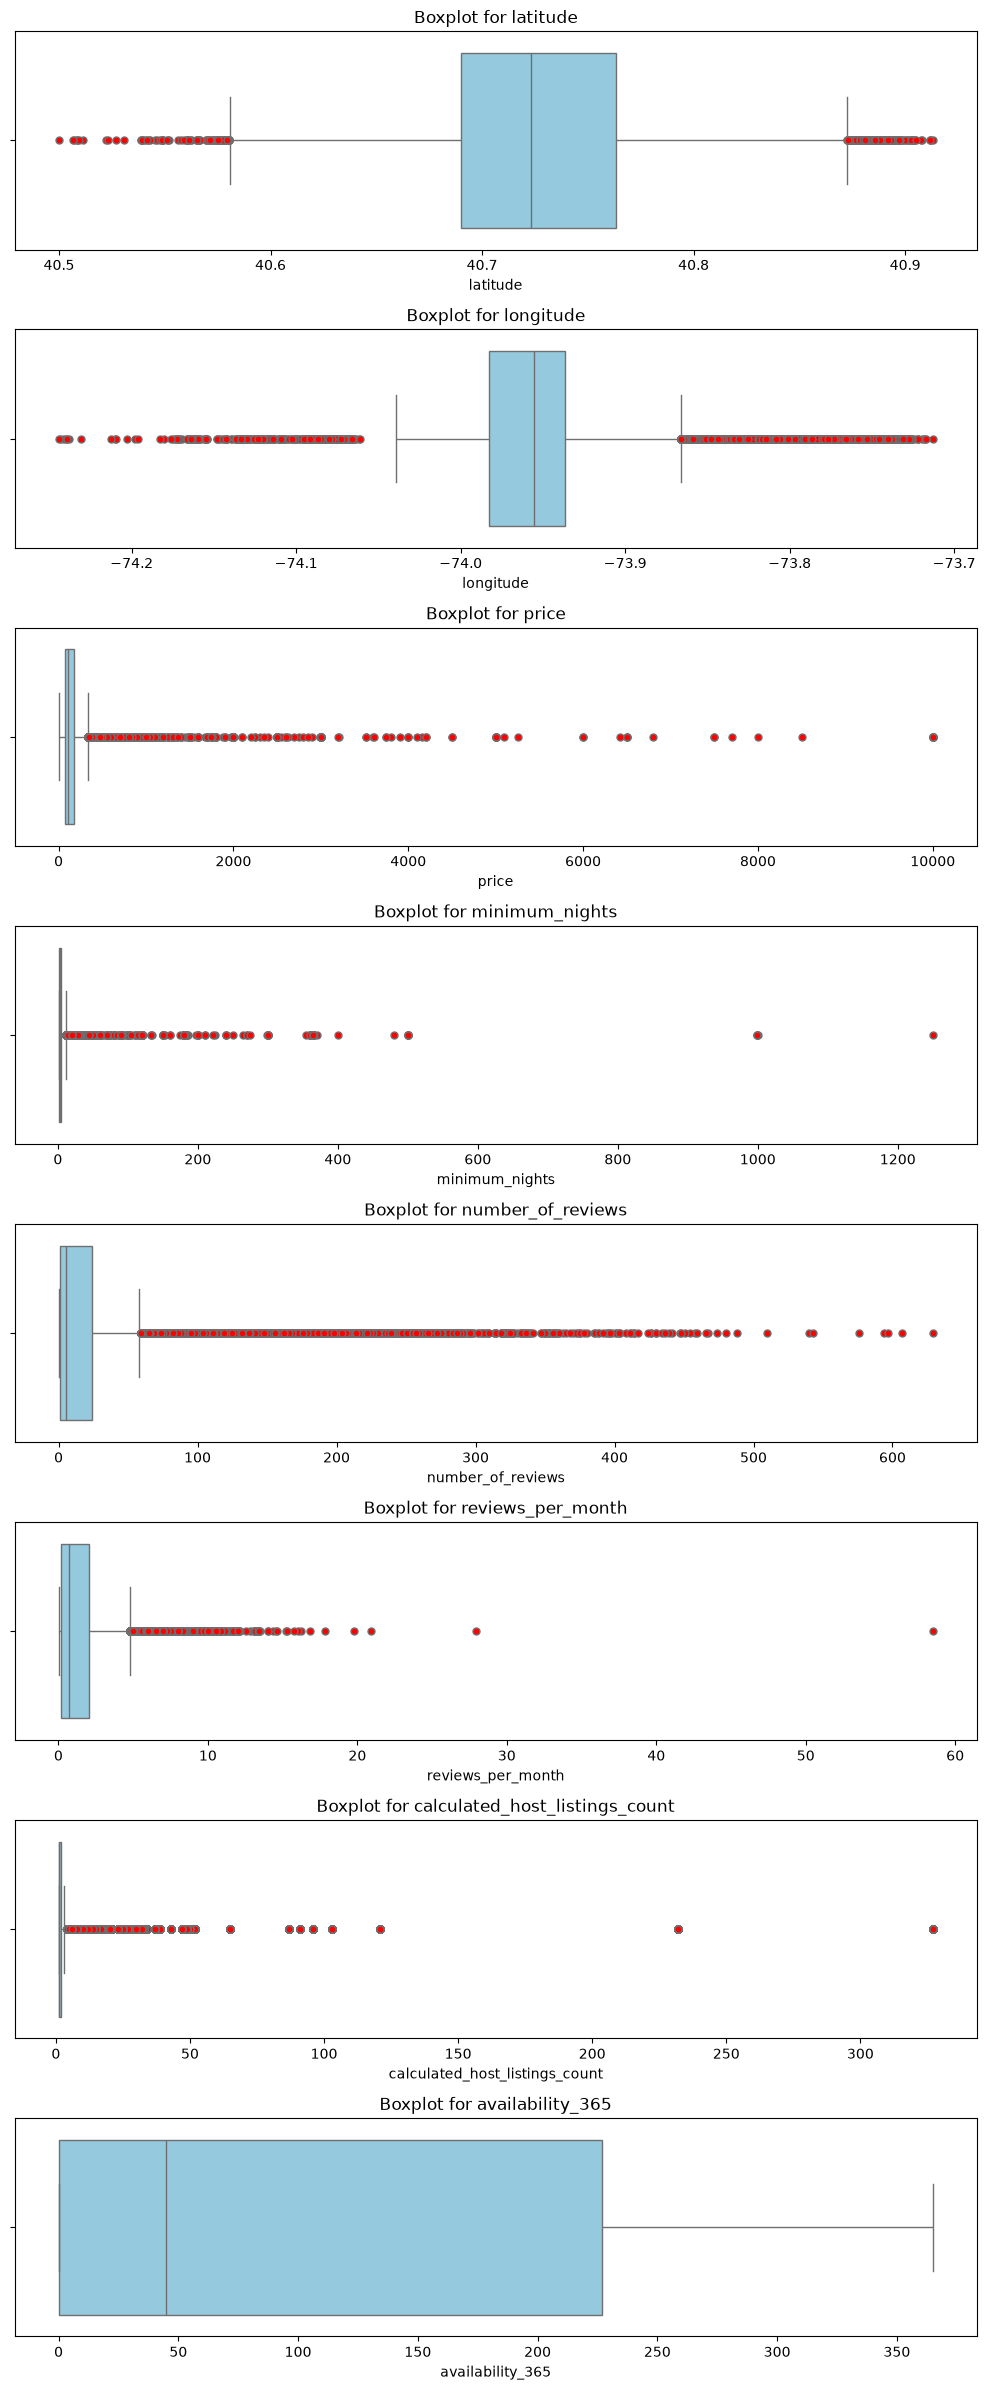

Suspected Outliers Summary
Feature: latitude
  - Total Outlier Count: 425 (0.87% of data)
  - Sample Outlier Values: [np.float64(40.4998), np.float64(40.5064), np.float64(40.5071), np.float64(40.5087), np.float64(40.5087), np.float64(40.5094), np.float64(40.5113), np.float64(40.5221), np.float64(40.5229), np.float64(40.527)]...

Feature: longitude
  - Total Outlier Count: 2833 (5.79% of data)
  - Sample Outlier Values: [np.float64(-74.2444), np.float64(-74.2428), np.float64(-74.2408), np.float64(-74.2399), np.float64(-74.2391), np.float64(-74.238), np.float64(-74.2306), np.float64(-74.2124), np.float64(-74.2102), np.float64(-74.2094)]...

Feature: price
  - Total Outlier Count: 2972 (6.08% of data)
  - Sample Outlier Values: [np.int64(335), np.int64(336), np.int64(337), np.int64(338), np.int64(339), np.int64(340), np.int64(341), np.int64(342), np.int64(343), np.int64(344)]...

Feature: minimum_nights
  - Total Outlier Count: 6607 (13.51% of data)
  - Sample Outlier Values: [np.int64(12

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=len(features), ncols=1, figsize=(10, 3 * len(features))
)

if len(features) == 1:
    axes = [axes]

outliers_summary = {}

for ax, col in zip(axes, features):
    sns.boxplot(
        x=df[col],
        ax=ax,
        color='skyblue',
        flierprops={'markerfacecolor': 'red', 'marker': 'o', 'markersize': 5},
    )
    ax.set_title(f'Boxplot for {col}', fontsize=12)

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][
        col
    ].dropna()
    outliers_summary[col] = outliers

plt.tight_layout()
plt.show()

print("Suspected Outliers Summary")
for col, outliers in outliers_summary.items():
    unique_vals = [
        round(val, 4) if isinstance(val, float) else val
        for val in sorted(outliers.unique())
    ]
    print(
        f"Feature: {col}\n"
        f"  - Total Outlier Count: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)\n"
        f"  - Sample Outlier Values: {unique_vals[:10]}...\n"
    )

1.3 A3. Handling Missing Data (0.5)

In [86]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

2. Apply three imputation methods:

In [87]:
import numpy as np
from sklearn.impute import KNNImputer

mean_before = df['reviews_per_month'].mean().round(2)
std_before = df['reviews_per_month'].std().round(2)

# Constant value
df['reviews_const'] = df['reviews_per_month'].fillna(0)


# Mean/Median/Mode: Mean
df['reviews_mean'] = df['reviews_per_month'].fillna(df['reviews_per_month'].mean())

# Predictive Imputation (KNN Imputer)
knn_cols = ['latitude', 'longitude', 'price', 'minimum_nights', 'reviews_per_month']
knn_imputer = KNNImputer(n_neighbors=5)
knn_result = knn_imputer.fit_transform(df[knn_cols])
df['reviews_knn'] = knn_result[:, -1]

comparison_results = pd.DataFrame([
    {'Method': 'Before Imputation', 'Mean': mean_before, 'Std Dev': std_before},
    {'Method': '1. Constant Imputation (0)', 'Mean': df['reviews_const'].mean(), 'Std Dev': df['reviews_const'].std()},
    {'Method': '2. Mean Imputation', 'Mean': df['reviews_mean'].mean(), 'Std Dev': df['reviews_mean'].std()},
    {'Method': '3. Predictive (KNN)', 'Mean': df['reviews_knn'].mean(), 'Std Dev': df['reviews_knn'].std()}
]).set_index('Method')

comparison_results.round(4)

,Mean,Std Dev
Method,,
Before Imputation,1.3700,1.6800
1. Constant Imputation (0),1.0909,1.5973
2. Mean Imputation,1.3732,1.4978
3. Predictive (KNN),1.3265,1.5623


4. Briefly discuss advantages and disadvantages of each method.

Mean Imputation is the most suitable method for preserving the central tendency, as replacing missing values with the column mean keeps the center of distribution identical. However because all missing entries are replaced by a single identical value, the overall spread of the data shrinks, artificially reducing the variance and standard deviation.

Predictive Imputation (KNN Imputer) is the best option for maintaining the overall spread and variability of the dataset. By analyzing feature patterns across nearest neighbors, it inserts realistic values, keeping the standard deviation closest to the original. It is computationally expensive and slow on large datasets, requires scaling/preprocessing of numeric features, and slightly shifts the mean compared to mean imputation. 

Constant Imputation is the easiest way with no calculations, however it significantly shifts the mean toward zero and distorts both the distribution and standard deviation, causing severe data distortion.

2 Level B — Medium

1. Select at least two numeric features with different scales. 
    Price (10-10.000)
    Minimum nights(1-365)

In [88]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
features = ['price', 'minimum_nights']

df_minmax = df.copy()
df_zscore = df.copy()

# Min–Max Normalization
scaler_minmax = MinMaxScaler(feature_range=(0, 1))
df_minmax[features] = scaler_minmax.fit_transform(df[features])

# Z-score Standardization 
scaler_zscore = StandardScaler()
df_zscore[features] = scaler_zscore.fit_transform(df[features])

print("=== Original data ===")
print(df[features].head())

print("\n=== After Min-Max Normalization [0, 1] ===")
print(df_minmax[features].head())

print("\n=== After Z-score Standardization ===")
print(df_zscore[features].head())

=== Original data ===
   price  minimum_nights
0    149               1
1    225               1
2    150               3
3     89               1
4     80              10

=== After Min-Max Normalization [0, 1] ===
    price  minimum_nights
0  0.0149        0.000000
1  0.0225        0.000000
2  0.0150        0.001601
3  0.0089        0.000000
4  0.0080        0.007206

=== After Z-score Standardization ===
      price  minimum_nights
0 -0.015493       -0.293996
1  0.300974       -0.293996
2 -0.011329       -0.196484
3 -0.265335       -0.293996
4 -0.302811        0.144807


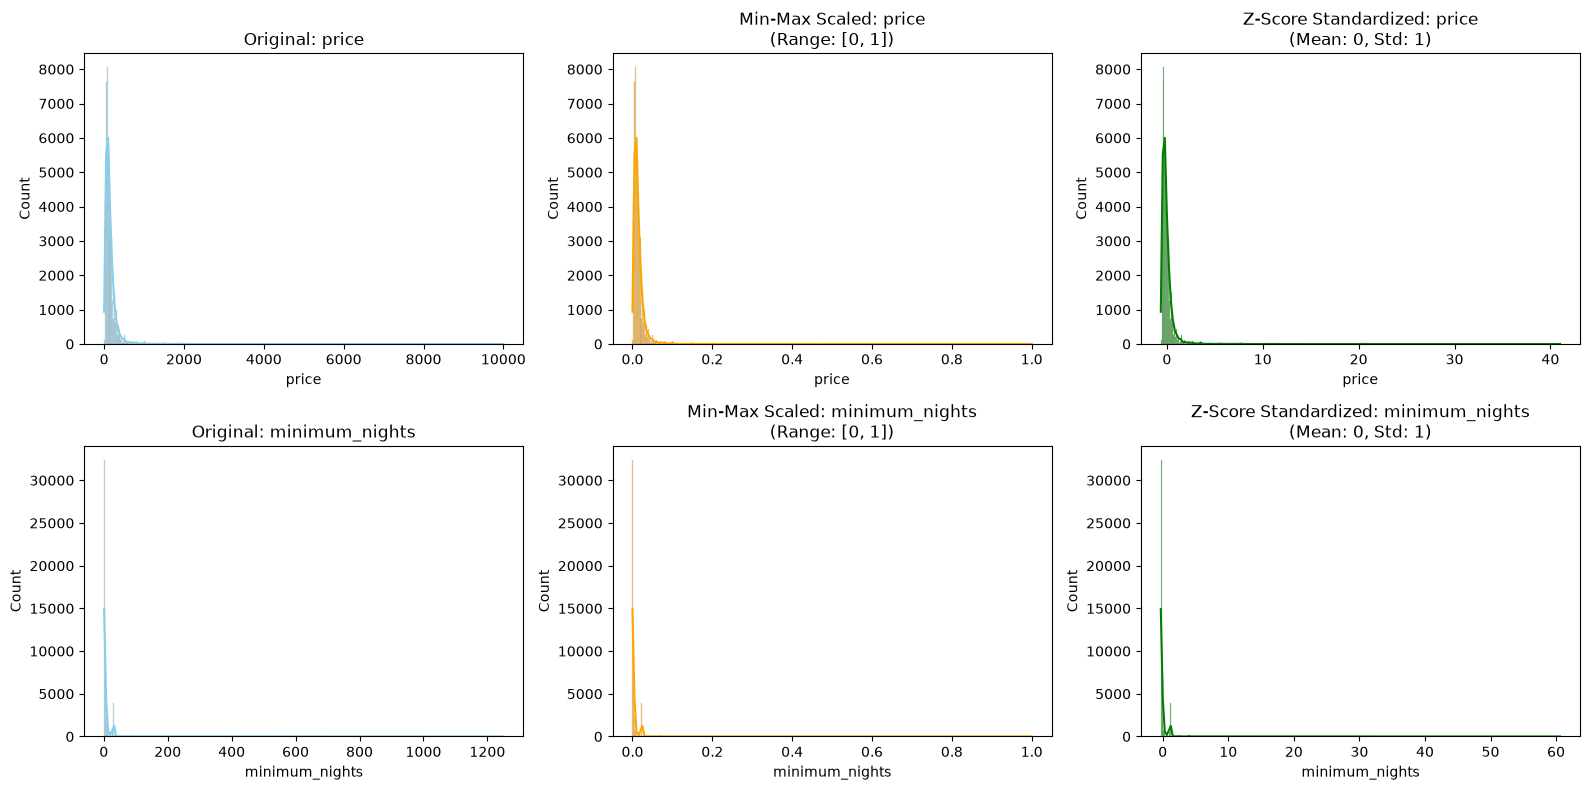

In [89]:
features = ['price', 'minimum_nights']

scaler_minmax = MinMaxScaler()
scaler_zscore = StandardScaler()

df_minmax = df.copy()
df_zscore = df.copy()

df_minmax[features] = scaler_minmax.fit_transform(df[features])
df_zscore[features] = scaler_zscore.fit_transform(df[features])

fig, axes = plt.subplots(nrows=len(features), ncols=3, figsize=(16, 8))

for i, feature in enumerate(features):
    sns.histplot(df[feature], ax=axes[i, 0], kde=True, color='skyblue')
    axes[i, 0].set_title(f'Original: {feature}')
    
    # Min-Max Normalization [0, 1]
    sns.histplot(df_minmax[feature], ax=axes[i, 1], kde=True, color='orange')
    axes[i, 1].set_title(f'Min-Max Scaled: {feature}\n(Range: [0, 1])')
    
    # Z-score Standardization
    sns.histplot(df_zscore[feature], ax=axes[i, 2], kde=True, color='green')
    axes[i, 2].set_title(f'Z-Score Standardized: {feature}\n(Mean: 0, Std: 1)')

plt.tight_layout()
plt.show()

Min-Max Normalization boundedly scales data strictly to [0, 1], making it sensitive to outliers which can compress non-outlier values. Z-Score Standardization centers data around a mean of 0 with a standard deviation of 1 without upper/lower boundaries, preserving data structure better in the presence of anomalies. Min-Max is preferable when exact, fixed boundaries are required, whereas Z-score is the default choice for models sensitive to variance or datasets with noise.

2.2 B2. Feature Creation & Discretization

1. Create one new feature using domain logic.

In [90]:
df["estimated_revenue"] = (
    df["price"] * df["minimum_nights"] * df["number_of_reviews"]
)

print(
    df[["price", "minimum_nights", "number_of_reviews", "estimated_revenue"]].head()
)

   price  minimum_nights  number_of_reviews  estimated_revenue
0    149               1                  9               1341
1    225               1                 45              10125
2    150               3                  0                  0
3     89               1                270              24030
4     80              10                  9               7200


2. Apply discretization using (and after compare bin counts and boundaries):

• Equal-width binning,

• Equal-frequency binning.

In [91]:
import matplotlib.pyplot as plt

df["price_equal_width"], width_bins = pd.cut(
    df["price"], bins=5, labels=["Very Low", "Low", "Medium", "High", "Very High"], retbins=True
)

df["price_equal_freq"], freq_bins = pd.qcut(
    df["price"], q=5, labels=["Very Low", "Low", "Medium", "High", "Very High"], retbins=True
)

print("=== Equal-Width Boundaries ===")
print(width_bins)
print("\nEqual-Width Bin Counts:")
print(df["price_equal_width"].value_counts())

print("\n=== Equal-Frequency Boundaries ===")
print(freq_bins)
print("\nEqual-Frequency Bin Counts:")
print(df["price_equal_freq"].value_counts())

=== Equal-Width Boundaries ===
[  -10.  2000.  4000.  6000.  8000. 10000.]

Equal-Width Bin Counts:
price_equal_width
Very Low     48809
Low             54
Medium          16
High             9
Very High        7
Name: count, dtype: int64

=== Equal-Frequency Boundaries ===
[    0.    60.    90.   130.   200. 10000.]

Equal-Frequency Bin Counts:
price_equal_freq
High         10809
Very Low     10063
Low           9835
Medium        9804
Very High     8384
Name: count, dtype: int64


3. Convert categorical variables using one-hot encoding.

In [92]:

categorical_cols = ["room_type", "neighbourhood_group"]

df_encoded = pd.get_dummies(
    df, columns=categorical_cols, drop_first=False, dtype=int
)

encoded_cols = [
    col
    for col in df_encoded.columns
    if any(col.startswith(c) for c in categorical_cols)
]
print(df_encoded[encoded_cols].head())

   room_type_Entire home/apt  room_type_Private room  room_type_Shared room  \
0                          0                       1                      0   
1                          1                       0                      0   
2                          0                       1                      0   
3                          1                       0                      0   
4                          1                       0                      0   

   neighbourhood_group_Bronx  neighbourhood_group_Brooklyn  \
0                          0                             1   
1                          0                             0   
2                          0                             0   
3                          0                             1   
4                          0                             0   

   neighbourhood_group_Manhattan  neighbourhood_group_Queens  \
0                              0                           0   
1                       

4. Discuss how these transformations may impact ML models.

Domain feature creation captures critical non-linear interactions directly, providing stronger predictive signals for linear models and decision trees. Discretization smooths out noise and mitigates extreme outliers, but it inevitably causes information loss by discarding granular continuous variance. Equal-width binning often leads to sparse, unbalanced groups when data is skewed, whereas equal-frequency binning distorts true numerical scale distances. Finally, One-Hot Encoding allows non-ordinal categorical variables to be processed by algorithms requiring numeric input without imposing false order, though high-cardinality features significantly expand feature dimensionality.

3 Additional Analytical Tasks

3.1 D1. Measures of Similarity and Dissimilarity

1. Calculate Euclidean distance between two numeric vectors:

In [93]:
import numpy
a = np.array([1, 2,3,4,5])
b = np.array([6,7,8,9,10])

dist_np = np.linalg.norm(a-b)
print(dist_np)

11.180339887498949


2. Compute Jaccard similarity between two sets:

In [94]:
a = {"December", "January", "February", "March", "April", "May", "June", "July"}
b = {"April", "May", "June", "July", "August", "September", "October", "November"}
jaccard_sim = len(a.intersection(b)) / len(a.union(b))
print (jaccard_sim)


0.3333333333333333


3. Calculate between two numeric vectors:
• Cosine similarity,

In [95]:
a = np.array([1, 2,3,4,5])
b = np.array([6,7,8,9,10])

dot_product = np.dot(a,b)
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)
cosine_sim = dot_product/(norm_a * norm_b)
print(cosine_sim)

0.9649505047327671


3. Calculate between two numeric vectors:
• Pearson correlation coefficient.

In [96]:
a = np.array([1, 2,3,4,5])
b = np.array([6,7,8,9,10])

a_centered = a - np.mean(a)
b_centered = b - np.mean(b)
pearson_corr = np.dot(a_centered, b_centered)/(np.linalg.norm(a_centered)* np.linalg.norm(b_centered))
print(pearson_corr)

0.9999999999999998


Write a short explanation of each metric.

Euclidean distance is the shortest geometric distance between two points/vectors in space.

Jaccard similarity is a statistical measure that shows how similar two sets are based on their overlap.

Cosine similarity is a metric used to measure how similar two vectors are by evaluating the cosine of the angle between them.

Pearson correlation coefficient calculates the strength and direction of a linear relationship between two variables.

5. Compare numerical results and explain why they differ.

In [97]:
import numpy as np

a = np.array([1, 2, 3, 4, 5])
b = np.array([6, 7, 8, 9, 10])

dist_np = np.linalg.norm(a - b)


set_a = {
    "December",
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
}
set_b = {
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
}

jaccard_sim = len(set_a.intersection(set_b)) / len(set_a.union(set_b)) 

dot_product = np.dot(a, b)
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)
cosine_sim = dot_product / (norm_a * norm_b)

a_centered = a - np.mean(a)
b_centered = b - np.mean(b)
pearson_corr = np.dot(a_centered, b_centered) / (np.linalg.norm(a_centered) * np.linalg.norm(b_centered))

print(f"Euclidean Distance: {dist_np:.4f}")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")
print(f"Cosine Similarity:  {cosine_sim:.4f}")
print(f"Pearson Correlation:{pearson_corr:.4f}")

Euclidean Distance: 11.1803
Jaccard Similarity: 0.3333
Cosine Similarity:  0.9650
Pearson Correlation:1.0000


Euclidean Distance (11.1803) is large because it measures absolute magnitude/scale differences. Vector b is shifted by +5 at every point relative to vector a.

Jaccard Similarity (0.3333) measures category overlap between sets (4 shared months out of 12 total).

Cosine Similarity (0.9650) is high because it ignores absolute values and measures vector direction from the origin; both vectors share a strongly positive upward slope.

Pearson Correlation (1.0000) is a perfect 1.0 because it applies mean-centering before computing direction, which completely eliminates the +5 offset and reveals a perfect linear relationship.

3.2 D2. Dimensionality Reduction (PCA)

1. Standardize features.

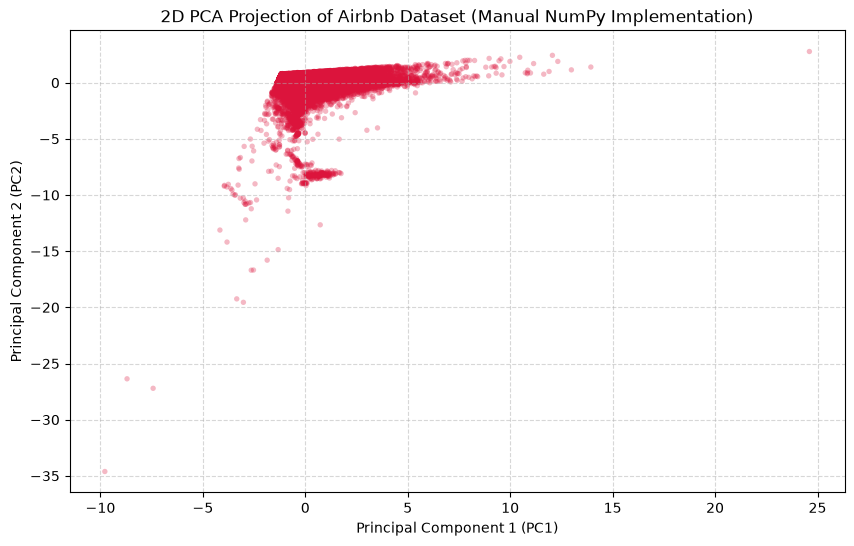

In [98]:
numeric_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
]
data = df[numeric_cols].dropna().to_numpy()

# 1. Standardize features

mean = np.mean(data, axis = 0)
std = np.std(data, axis = 0)
X_std = (data- mean)/ std

# 2. Compute the covariance matrix.

cov_matrix = np.cov(X_std, rowvar = False)

# 3. Find eigenvalues and eigenvectors.
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

#4. Select the two largest eigenvalues.
idx = np.argsort(eigenvalues)[::-1]
eigenvalues_sorted = eigenvalues[idx]
eigenvectors_sorted = eigenvectors[:, idx]

W = eigenvectors_sorted[:,:2] 

#5. Project data onto the corresponding eigenvectors.
X_pca = np.dot(X_std, W)


# 6. Plot the 2D result using matplotlib.
plt.figure(figsize = (10,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha = 0.3, c = "crimson", edgecolors="none", s= 15)
plt.title("2D PCA Projection of Airbnb Dataset (Manual NumPy Implementation)")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

7. Briefly explain:

• What each step means,

• What eigenvalues represent,

• What the PCA visualization shows.

Firstly, i standardized the data so, scales features to mean = 0 and variance = 1 so that high-magnitude variables do not dominate variables with smaller scales. then i computed covariance matrix which measures how pairs of numerical columns change together and shows the overall variance (spread) of the data. eigenvectors and eigenvalues were needed to identify the principal directions of maximum variance and their corresponding magnitudes. largest eigenvalues preserve the highest proportion of the dataset's total variance. then i show all data as 2d subspace defined by the top two principal components. 

Eigenvalues represent amount of variance captured along each corresponding eigenvector. A larger eigenvalue signifies a more important direction that retains a higher portion of the original dataset's variability

PCA visualization shows high-dimensional data in a simplified 2D coordinate system.It helps easily identify common patterns.

8. Compare the original data structure with the reduced 2D projection.

1. Dimensions & Complexity:

Original Data: High-dimensional .

Reduced 2D Projection: Low-dimensional .
2. Feature Correlation & Redundancy:

Original Data:Contains linear correlations and multicollinearity between features .

Reduced 2D Projection:PC1 and PC2 are completely uncorrelated axes, removing linear redundancy.

3. Information & Variance:
 
Original Data: Retains 100% of the original variance and granular unit metrics .


Reduced 2D Projection: Retains the majority of the variance , but intentionally discards minor variance to reduce dimensionality.

4. Visual Interpretability:
   
Original Data: Difficult to visualize directly as a single plot due to multi-dimensional space.

Reduced 2D Projection: Easily rendered as a 2D scatter plot, making global patterns, dense clusters, and severe outliers immediately visible.

4 Level C — Difficult

4.1 C1. Advanced Sampling & Data Quality Analysis (1)


1. Choose a public dataset with at least 20,000 rows, a meaningful categorical variable for
stratification, and a natural cluster identifier 

Airbnb dataset is suitable (48895 rows)

2. Create:
(a) Simple Random Sample (10%),
(b) Stratified sample,
(c) Cluster sample (justify).

Full Dataset Size: 48895
SRS Size: 4890
Stratified Size: 4890
Cluster Size: 3589

Descriptive Statistics Comparison (Price)
                    Mean  Median      Variance    IQR
Full Dataset  152.720687   106.0  57674.025247  106.0
SRS (10%)     148.915542   100.0  61539.959525  109.0
Stratified    150.731902   105.0  40530.161081  106.0
Cluster       110.550014    85.0  18306.343443   66.0


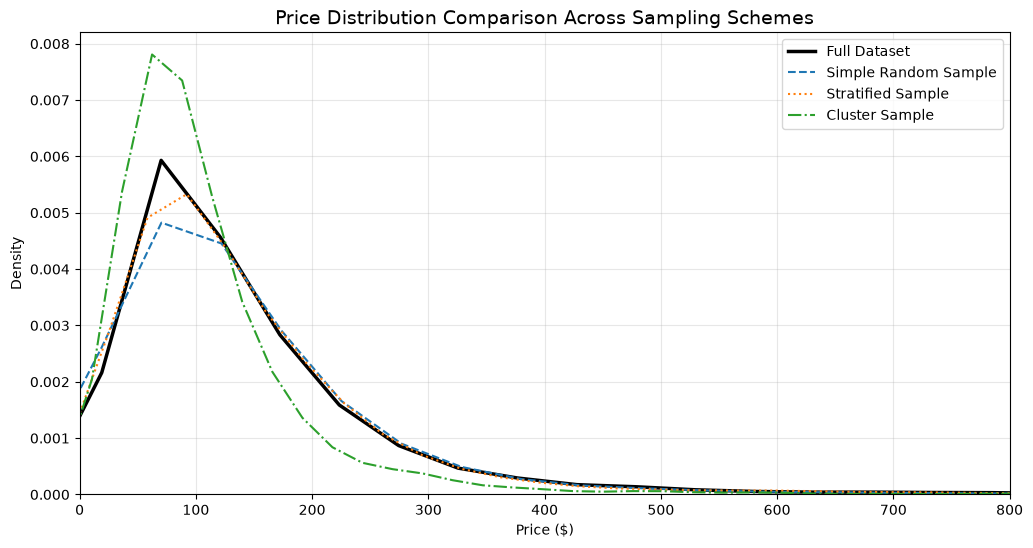

In [99]:
df = df.dropna(subset=['price'])
# (a) Simple Random Sample
srs_sample = df.sample(frac=0.10, random_state=42)

#(b) Stratified sample
stratified_sample = df.groupby('room_type', group_keys = False).apply(
    lambda x: x.sample(frac = 0.10, random_state = 42)
)
# (c) Cluster sample

np.random.seed(42)
unique_clusters = df['neighbourhood'].unique()
num_clusters = max(1, int(len(unique_clusters) * 0.10))
sampled_clusters = np.random.choice(unique_clusters, size = num_clusters, replace = False)
cluster_sample = df[df['neighbourhood'].isin(sampled_clusters)]


print(f"Full Dataset Size: {len(df)}")
print(f"SRS Size: {len(srs_sample)}")
print(f"Stratified Size: {len(stratified_sample)}")
print(f"Cluster Size: {len(cluster_sample)}")

# 3. Compute descriptive statistics (mean, median, variance, IQR).

def get_stats(data, col_name = 'price'):
    series = data[col_name]
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    return{
        'Mean': series.mean(),
        'Median':series.median(),
        'Variance': series.var(),
        'IQR': Q3 - Q1
    }

stats_df = pd.DataFrame({
    'Full Dataset': get_stats(df),
    'SRS (10%)': get_stats(srs_sample),
    'Stratified': get_stats(stratified_sample),
    'Cluster': get_stats(cluster_sample)
}).T

print("\nDescriptive Statistics Comparison (Price)")
print(stats_df)


# 4. Visualize distributions vs. full dataset.

plt.figure(figsize=(12, 6))


sns.kdeplot(df['price'], label='Full Dataset', color='black', linewidth=2.5)
sns.kdeplot(srs_sample['price'], label='Simple Random Sample', linestyle='--')
sns.kdeplot(stratified_sample['price'], label='Stratified Sample', linestyle=':')
sns.kdeplot(cluster_sample['price'], label='Cluster Sample', linestyle='-.')

plt.xlim(0, 800)
plt.title('Price Distribution Comparison Across Sampling Schemes', fontsize=14)
plt.xlabel('Price ($)')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

5. Write a short analytical report discussing:
• Which sampling method preserved distributions best,
• Impact on outlier detection,
• Recommendations for real-world projects.

From the graphic , it can be seen that Stratified Sample preserved the population distribution most accurately, with its Median (105.0) and IQR (106.0) almost perfectly matching the Full Dataset (106.0 for both). however it did not detect outliers (at 0.006) well. cluster sample performed the worst; random selection of geographic clusters introduced heavy sampling bias, severely underestimating the mean (110.55 vs 152.72) and variance. simple random sample was a close second due to the large sample size , capturing the general density profile effectively.

For real-world projects it is better to use Stratified Sampling when maintaining correct population ratios of key subgroups is critical for downstream modeling. Cluster Sampling may be good choice only when logistical, computational, or financial costs make gathering data across all groups impossible, and apply weight corrections to mitigate cluster bias.